# 03 · Preprocessing (Member A)

Cleans the LBNL chiller plant data and adds the team's derived metrics.

**What this notebook shows**
1. Rows before and after cleaning (frozen-sensor removal, then 3-sigma outliers)
2. Hours with chillers on, per month
3. Histograms of `CHL_COP_1` and `PLANT_COP`

All logic lives in `src/preprocess.py`; this notebook only runs it and plots the results.
Set `DATA_DIR` in your `.env` to the folder with the 24 CSV files. Settings come from `config.yaml` (`preprocess.sigma`, `preprocess.frozen_window`).

In [1]:
import os, sys
from pathlib import Path
if Path.cwd().name == "notebooks":          # run from the repo root
    os.chdir("..")
sys.path.insert(0, str(Path.cwd()))

import pandas as pd
import matplotlib.pyplot as plt
from src import preprocess as pp

S = pp.load_settings("config.yaml")
pd.set_option("display.width", 140)
S

{'n_chillers': 3,
 'n_towers': 3,
 'frozen_window': 60,
 'frozen_tol': 1e-06,
 'sigma': 3,
 'max_flag_frac': 0.2,
 'min_chiller_kw': 1.0,
 'min_plant_kw': 1.0,
 'min_cool_kw': 50.0,
 'sigma_by_month': True,
 'outliers_on_fault_files': False,
 'frozen_exclude': ['OA_TEMP', 'OA_TEMP_WB'],
 'tiny': 1e-09,
 'raw_dir': 'data/raw',
 'processed_dir': 'data/processed',
 'fault_free_file': 'ChillerPlant.csv'}

## Pick the files
The fault-free year sets the outlier limits. One fault file is processed alongside it as an example.

In [2]:
files = pp.list_files(pp.data_dir(S["raw_dir"]))
FAULT_FREE = pp.find_fault_free(files, S["fault_free_file"])      # ChillerPlant.csv
# example fault file: cooling tower 1 fouling if present (change to any scenario)
FAULT_FILE = next((f for f in files if "coolingtower_fouling" in f.name),
                  next(f for f in files if f != FAULT_FREE))
print(len(files), "CSV files found")
print("fault-free :", FAULT_FREE.name)
print("example    :", FAULT_FILE.name)

24 CSV files found
fault-free : ChillerPlant.csv
example    : ChillerPlant_coolingtower_fouling_065.csv


## Outlier limits from the fault-free year
Mean ± 3 std per sensor and calendar month (so normal summer peaks are not outliers), using only minutes when its equipment is running. Fault files skip this step by default (`outliers_on_fault_files: false`), because it would delete the fault signal itself.

In [3]:
ff_raw = pp.load_csv(FAULT_FREE)
limits = pp.fit_limits(ff_raw, S)
print(ff_raw.shape, "| sensors with limits:", limits.index.get_level_values(0).nunique())
limits.round(2).head(12)

(525540, 77) | sensors with limits: 53


mean     std     low     high
sensor       month                                 
CDWL_CW_FLOW 1      321.58    0.00  321.58   321.58
             2      321.58    0.00  321.58   321.58
             3      321.58    0.00  321.58   321.58
             4      341.66   77.80  108.27   575.04
             5      345.57   85.81   88.13   603.01
             6      420.36  148.87  -26.24   866.97
             7      483.24  182.34  -63.79  1030.27
             8      453.13  166.09  -45.15   951.42
             9      378.68  123.89    7.00   750.36
             10     321.58    0.00  321.58   321.58
             11     321.58    0.00  321.58   321.58
             12     321.58    0.00  321.58   321.58

## 1 · Rows before and after cleaning

In [4]:
results = {}
for f in [FAULT_FREE, FAULT_FILE]:
    raw, full, rep, saved = pp.process_file(f, limits, S)
    results[f.name] = (raw, full, rep)
    print("saved", saved)

summary = pd.DataFrame({
    name: {
        "raw rows": r["rows_raw"],
        "after frozen-sensor removal": r["rows_after_frozen"],
        "after 3-sigma removal": r["rows_after_outliers"],
        "rows removed": r["rows_raw"] - r["rows_after_outliers"],
        "% kept": round(100 * r["rows_after_outliers"] / r["rows_raw"], 2),
    } for name, (_, _, r) in results.items()
}).T
summary

saved data\processed\ChillerPlant.parquet
saved data\processed\ChillerPlant_coolingtower_fouling_065.parquet


,raw rows,after frozen-sensor removal,after 3-sigma removal,rows removed,% kept
ChillerPlant.csv,525540.0,495947.0,455491.0,70049.0,86.67
ChillerPlant_coolingtower_fouling_065.csv,525540.0,495555.0,495555.0,29985.0,94.29


In [5]:
# Which sensors caused the removals, and which checks were skipped
for name, (_, _, r) in results.items():
    print(f"=== {name}")
    if not r["outlier_step_run"]:
        print("(3-sigma step not run on this fault file: outliers_on_fault_files is false)")
    print("frozen, top columns:\n", r["frozen_by_column"].head(8).to_string() or "  none")
    print("outliers, top columns:\n", r["outliers_by_column"].head(8).to_string() or "  none")
    if r["frozen_check_skipped"]:
        print("frozen check skipped (value held constant for long stretches, e.g. at a setpoint):",
              r["frozen_check_skipped"])
    if r["outlier_check_skipped"]:
        print("outlier check skipped (too many values outside the fault-free limits):",
              r["outlier_check_skipped"])
    print()

=== ChillerPlant.csv
frozen, top columns:
 CHL_POW_1          28833
CDWL_SW_TEMP        1231
CT_RW_TEMP_1        1193
CDWL_RW_TEMP        1192
CHL_RWCD_TEMP_1     1123
CHL_SWCD_TEMP_1      901
CT_POW_2             643
CT_SW_TEMP_1         487
outliers, top columns:
 CWL_SEC_LOAD       7781
CWL_SEC_SW_TEMP    7529
CHL_POW_1          7447
CWL_SEC_DP         6923
CDWL_SW_TEMP       6681
CHL_SWCD_TEMP_1    6680
CT_RW_TEMP_1       6668
CDWL_RW_TEMP       6667
frozen check skipped (value held constant for long stretches, e.g. at a setpoint): {'CDWL_CW_FLOW': 0.998, 'CDWL_PM_POW_1': 0.394, 'CDWL_PM_POW_2': 0.997, 'CDWL_PM_POW_3': 0.999, 'CHL_CD_FLOW_1': 0.997, 'CHL_CD_FLOW_2': 0.98, 'CHL_CD_FLOW_3': 0.817, 'CHL_CW_FLOW_1': 0.997, 'CHL_CW_FLOW_2': 0.98, 'CHL_CW_FLOW_3': 0.817, 'CHL_RW_TEMP_1': 0.484, 'CHL_SW_TEMP_1': 0.503, 'CT_FLOW_1': 0.39, 'CT_FLOW_2': 0.979, 'CT_FLOW_3': 0.814, 'CT_POW_1': 0.738, 'CWL_PRI_CW_FLOW': 0.998, 'CWL_PRI_PM_POW_1': 0.996, 'CWL_PRI_PM_POW_2': 0.997, 'CWL_PRI_PM_PO

## 2 · Hours with chillers on, per month
From the raw fault-free year (status columns are not changed by cleaning).

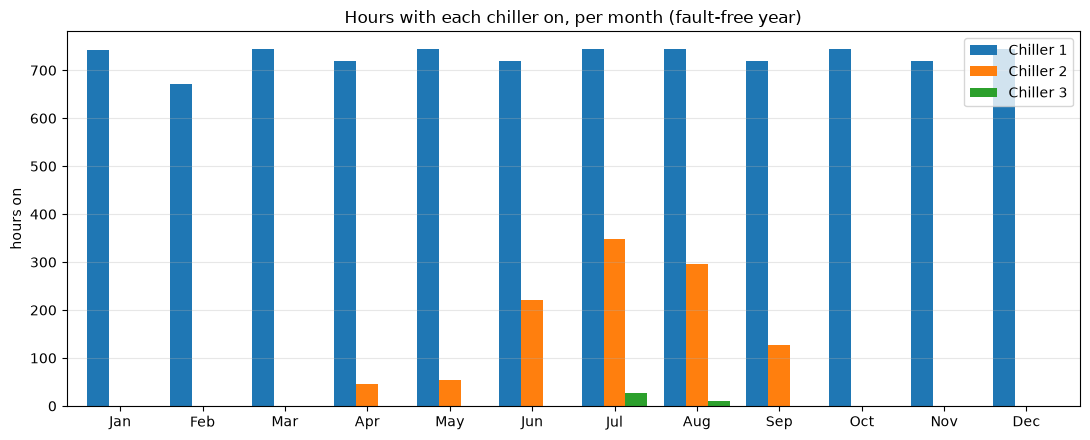

,Jan,Feb,Mar,Apr,May,Jun,Jul,Aug,Sep,Oct,Nov,Dec
Chiller 1,743.0,672.0,744.0,720.0,744.0,720.0,744.0,744.0,720.0,744.0,720.0,744.0
Chiller 2,0.0,0.0,0.0,45.0,54.7,220.6,347.4,295.0,127.0,0.0,0.0,0.0
Chiller 3,0.0,0.0,0.0,0.0,0.8,0.6,26.6,9.3,0.9,0.0,0.0,0.0


In [6]:
sta = ff_raw[[f"CHL_STA_{i}" for i in range(1, S["n_chillers"] + 1)]] > 0.5
hours = sta.groupby(sta.index.month).sum() / 60          # 1-minute data -> hours
hours.index = [pd.Timestamp(2018, m, 1).strftime("%b") for m in hours.index]
hours.columns = [f"Chiller {i}" for i in range(1, S["n_chillers"] + 1)]

ax = hours.plot.bar(figsize=(11, 4.5), width=0.8)
ax.set_ylabel("hours on"); ax.set_xlabel("")
ax.set_title("Hours with each chiller on, per month (fault-free year)")
ax.grid(axis="y", alpha=.3); plt.xticks(rotation=0); plt.tight_layout(); plt.show()
hours.round(1).T

## 3 · COP histograms
Only minutes with real cooling (≥ `min_cool_kw`, 50 kW by default); at near-zero winter load COP is meaningless. COP = cooling delivered ÷ electricity used. A healthy chiller is roughly 3–7; plant COP (building load `CWL_SEC_LOAD` ÷ plant power, as in `data/dataset_notes.md`) is lower because pumps and fans are included.

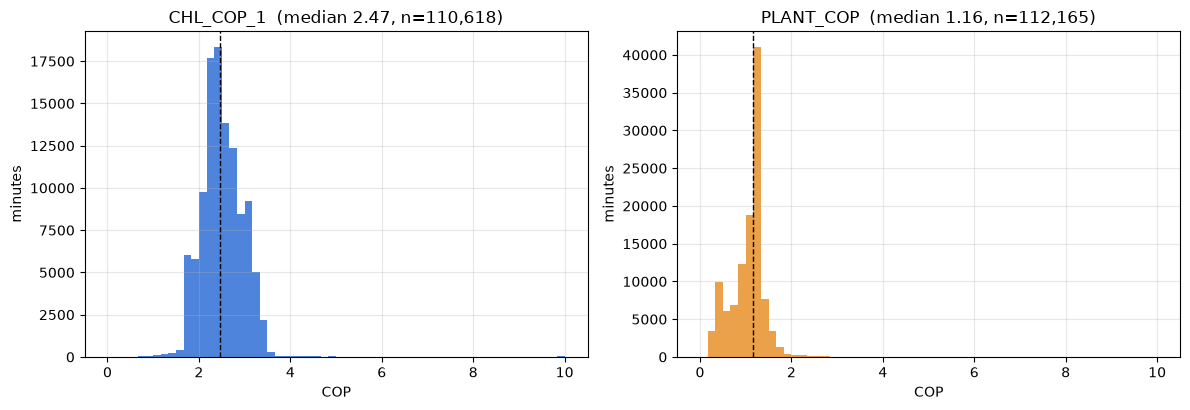

CHL_COP_1: 99.9% of values between 1 and 10
PLANT_COP: 65.7% of values between 1 and 10  <- check units / formula


In [7]:
ff_clean = results[FAULT_FREE.name][1]
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
for ax, col, colr in zip(axes, ["CHL_COP_1", "PLANT_COP"], ["#2f6fd6", "#e8902a"]):
    x = ff_clean[col].dropna()
    ax.hist(x.clip(0, 10), bins=60, range=(0, 10), color=colr, alpha=.85)
    ax.axvline(x.median(), color="k", ls="--", lw=1)
    ax.set_title(f"{col}  (median {x.median():.2f}, n={len(x):,})")
    ax.set_xlabel("COP"); ax.set_ylabel("minutes"); ax.grid(alpha=.3)
plt.tight_layout(); plt.show()

for col in ["CHL_COP_1", "PLANT_COP"]:
    x = ff_clean[col].dropna()
    share = ((x > 1) & (x < 10)).mean() * 100
    print(f"{col}: {share:.1f}% of values between 1 and 10"
          + ("" if share > 95 else "  <- check units / formula"))

## Derived columns added
Names agreed with the team (Member B uses them as graph nodes).

In [8]:
derived = [c for c in ff_clean.columns
           if c.startswith(("CHL_DT_", "CHL_COOL_", "CHL_COP_", "CHL_CDDT_", "CT_APPROACH_"))
           or c in ("PLANT_POW", "PLANT_COP")]
ff_clean[derived].describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
CHL_DT_1,455491.0,1.52,2.71,-1.15,0.10,0.10,1.03,15.10
CHL_COOL_1,455491.0,62.38,110.91,-47.01,4.28,4.28,42.10,617.99
CHL_COP_1,110618.0,2.52,0.64,0.40,2.22,2.47,2.81,61.24
CHL_CDDT_1,455491.0,1.50,2.64,-0.25,0.10,0.10,1.10,12.09
CHL_DT_2,55100.0,6.71,1.50,0.10,5.86,6.75,7.74,13.47
CHL_COOL_2,455491.0,33.23,92.08,0.00,0.00,0.00,0.00,548.51
CHL_COP_2,54339.0,2.29,0.49,0.52,2.09,2.29,2.49,45.30
CHL_CDDT_2,55100.0,6.59,1.48,-1.91,5.69,6.60,7.62,11.11
CHL_DT_3,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
CHL_COOL_3,455491.0,0.00,0.00,0.00,0.00,0.00,0.00,0.00


## Optional: process all 24 files
Takes a while (each file is ~0.5 M rows). Results go to `data/processed/`.

In [9]:
RUN_ALL = False
if RUN_ALL:
    rows = []
    for f in files:
        _, _, rep, saved = pp.process_file(f, limits, S)
        rows.append({"file": f.name, "raw": rep["rows_raw"], "clean": rep["rows_after_outliers"]})
        print(f.name, "done")
    pd.DataFrame(rows)